<a href="https://colab.research.google.com/github/EdgarAG-DF-UPC/Docencia-Fisica-1Sem-GEI_FIB-UPC/blob/main/FOURIER.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Edgar Alvarez Galera, 26 d’Octubre del 2026

**FÍSICA (F) – Grup 60 – Grau en Enginyeria Informàtica (FIB, UPC)**

**Curs 2026–27, Semestre de Tardor**

---

#2. CORRENT ALTERN.
##2.7. Superposició de senyals i Amplada de banda: **Sèries de Fourier**

In [ ]:
from math import pi as π
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
def A_pols_quadrat(n: int, A: float, ω0: float, t0: float, τ: float) -> float:
    # Coeficient An per a un pols rectangular d'amplitud A, durada τ i inici t0
    return (
        (2. * A / (n * π))
        * np.sin(n * ω0 * τ / 2.)
        * np.cos(n * ω0 * (t0 + τ / 2.))
    )


def B_pols_quadrat(n: int, A: float, ω0: float, t0: float, τ: float) -> float:
    # Coeficient Bn per a un pols rectangular d'amplitud A, durada τ i inici t0
    return (
        (2. * A / (n * π))
        * np.sin(n * ω0 * τ / 2.)
        * np.sin(n * ω0 * (t0 + τ / 2.))
    )

In [ ]:
def A_pols_triangular(n: int, A: float, ω0: float, t0: float, τ: float) -> float:
    # Coeficient An per a un pols triangular d'amplitud A, durada τ i inici t0
    t1 = t0 + τ
    terme_lineal = np.sin(n * ω0 * t1)
    terme_pendent = (1.0 / (n * ω0 * τ)) * (
        np.cos(n * ω0 * t1) - np.cos(n * ω0 * t0)
    )

    return (A / (n * π)) * (terme_lineal - terme_pendent)


def B_pols_triangular(n: int, A: float, ω0: float, t0: float, τ: float) -> float:
    # Coeficient Bn per a un pols triangular d'amplitud A, durada τ i inici t0
    t1 = t0 + τ
    terme_lineal = -np.cos(n * ω0 * t1)
    terme_pendent = (1.0 / (n * ω0 * τ)) * (
        np.sin(n * ω0 * t1) - np.sin(n * ω0 * t0)
    )

    return (A / (n * π)) * (terme_lineal + terme_pendent)

In [ ]:
def A_pols_sawtooth(n: int, A: float, ω0: float, t0: float, τ: float) -> float:
    # Coeficient An per a una denta de serra periòdica de període T (on τ = T)
    return -(A / (n * π)) * np.sin(n * ω0 * t0)


def B_pols_sawtooth(n: int, A: float, ω0: float, t0: float, τ: float) -> float:
    # Coeficient Bn per a una denta de serra periòdica de període T (on τ = T)
    return -(A / (n * π)) * np.cos(n * ω0 * t0)

In [ ]:
def A_pols_triangular_simetric(n: int, A: float, ω0: float, t0: float, τ: float) -> float:
    # Coeficient An per a un pols triangular simètric (puja i baixa)
    # n_w0_tau_4 és (n * ω0 * τ / 4)
    term = (4.0 * A / (n**2 * π * ω0 * τ)) * (np.sin(n * ω0 * τ / 4.0) ** 2)
    return 2.0 * term * np.cos(n * ω0 * (t0 + τ / 2.0))


def B_pols_triangular_simetric(n: int, A: float, ω0: float, t0: float, τ: float) -> float:
    # Coeficient Bn per a un pols triangular simètric (puja i baixa)
    term = (4.0 * A / (n**2 * π * ω0 * τ)) * (np.sin(n * ω0 * τ / 4.0) ** 2)
    return 2.0 * term * np.sin(n * ω0 * (t0 + τ / 2.0))

In [ ]:
from math import pi as π
import matplotlib.pyplot as plt
import numpy as np


def Fourier(
    wave: str,
    tmin: float,
    tmax: float,
    T: float,
    t0: float,
    τ: float,
    A: float,
    A_min: float,
    Nharms: int,
    **kwargs,
):
    llegenda = kwargs.get("legend", False)

    assert τ <= T, "La durada del pols τ no pot ser major que el període T"

    # 1. Càlcul del valor mitjà / Offset teòric (A0)
    # A0 = A_min + (Àrea del pols / T)
    if wave == "square":
        tipus = "Quadrat"
        A0 = A_min + (A * τ / T)
    elif wave == "triangular_sawtooth":
        tipus = "Triangular (Denta de Serra)"
        A0 = A_min + A/2
    elif wave == "triangular_sym":
        tipus = "Triangular Simètric"
        A0 = A_min + (A * τ / (2.0 * T))
    else:
        raise ValueError(
            "Tipus de senyal no vàlid. Utilitza: 'square', 'triangular_sawtooth', o 'triangular_sym'"
        )

    ω0 = 2.0 * π / T

    t = np.arange(tmin, tmax, 0.0001)  # Eix de temps
    total_amplitude = np.full_like(t, A0, dtype=float)

    plt.figure(figsize=(11, 6))

    # Dibuixa la línia del component continu (A0)
    plt.axhline(
        y=A0,
        color="black",
        linestyle=":",
        linewidth=1.5,
        label=f"A0 = {A0:.2f} (Offset)",
    )

    # Suma de cada harmònic
    for n in range(1, Nharms + 1):
        if wave == "square":
            A_n = A_pols_quadrat(n, A, ω0, t0, τ)
            B_n = B_pols_quadrat(n, A, ω0, t0, τ)
        elif wave == "triangular_sawtooth":
            A_n = A_pols_sawtooth(n, A, ω0, t0, τ)
            B_n = B_pols_sawtooth(n, A, ω0, t0, τ)
        elif wave == "triangular_sym":
            A_n = A_pols_triangular_simetric(n, A, ω0, t0, τ)
            B_n = B_pols_triangular_simetric(n, A, ω0, t0, τ)

        # Harmònic complet: An*cos(n*ω0*t) + Bn*sin(n*ω0*t)
        harmonic = A_n * np.cos(n * ω0 * t) + B_n * np.sin(n * ω0 * t)

        label = f"n = {n}" if llegenda else None
        plt.plot(t, harmonic, linestyle="--", alpha=0.35, label=label)

        total_amplitude += harmonic

    # Dibuixa la reconstrucció de Fourier
    plt.plot(
        t,
        total_amplitude,
        color="red",
        linewidth=2,
        label="Suma de Fourier",
    )

    plt.xlabel("t (s)")
    plt.ylabel("V(t)")
    plt.title(
        f"Sèrie de Fourier per a un Pols {tipus} (A={A}, A_min={A_min}, τ={τ}, T={T}, N={Nharms})"
    )
    plt.grid(True)
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
    plt.tight_layout()
    plt.show()

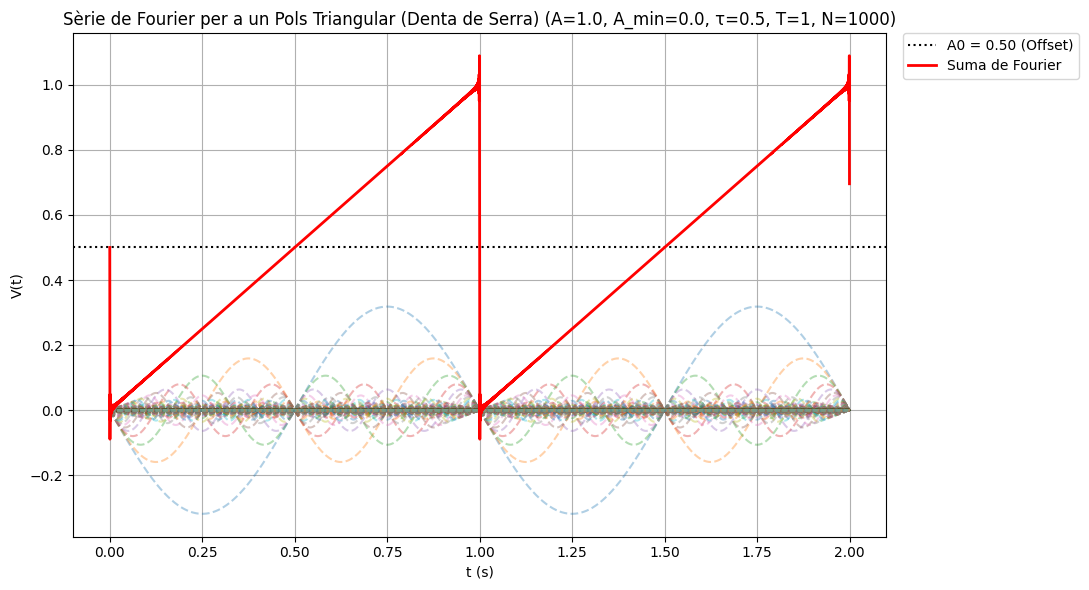

In [ ]:
Fourier(wave="triangular_sawtooth", tmin=0, tmax=2, T=1, t0=0, τ=0.5, A=1., A_min=0., Nharms=1000)

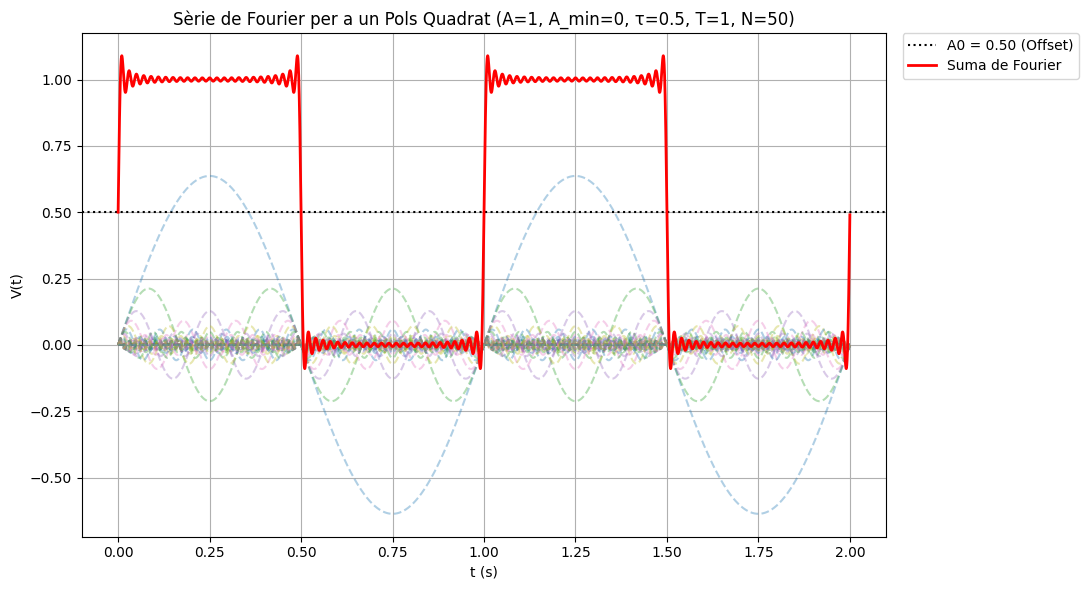

In [ ]:
Fourier(wave="square", tmin=0, tmax=2, T=1, t0=0, τ=0.5, A=1, A_min=0, Nharms=50)

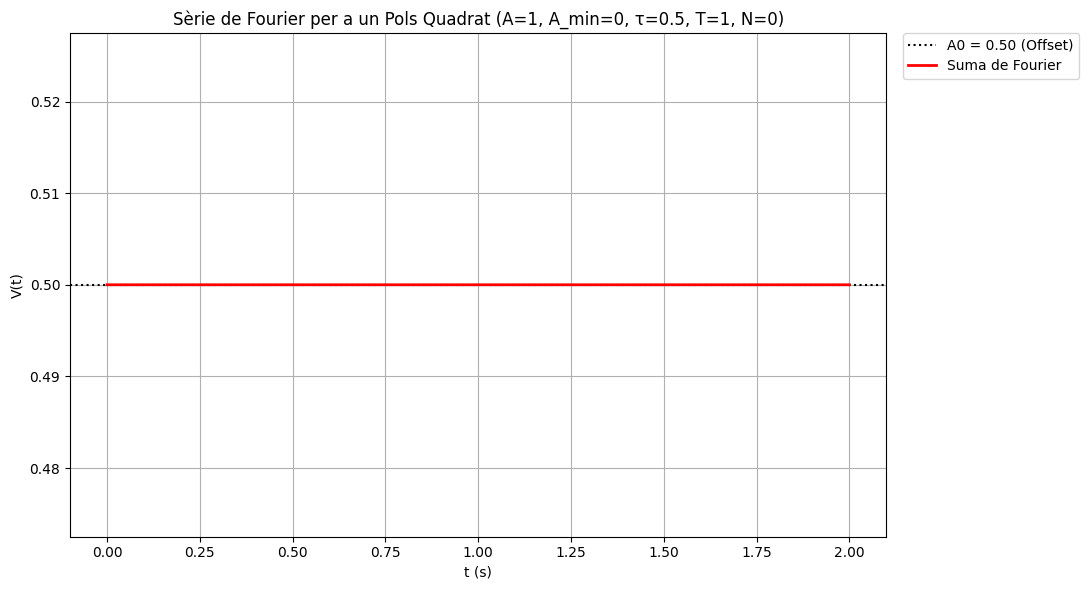

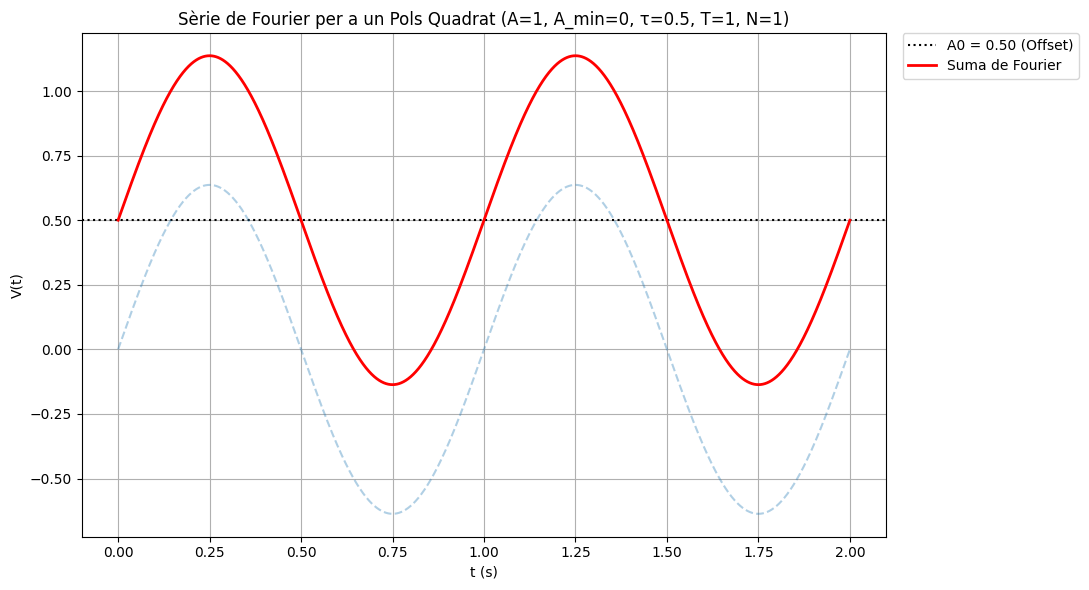

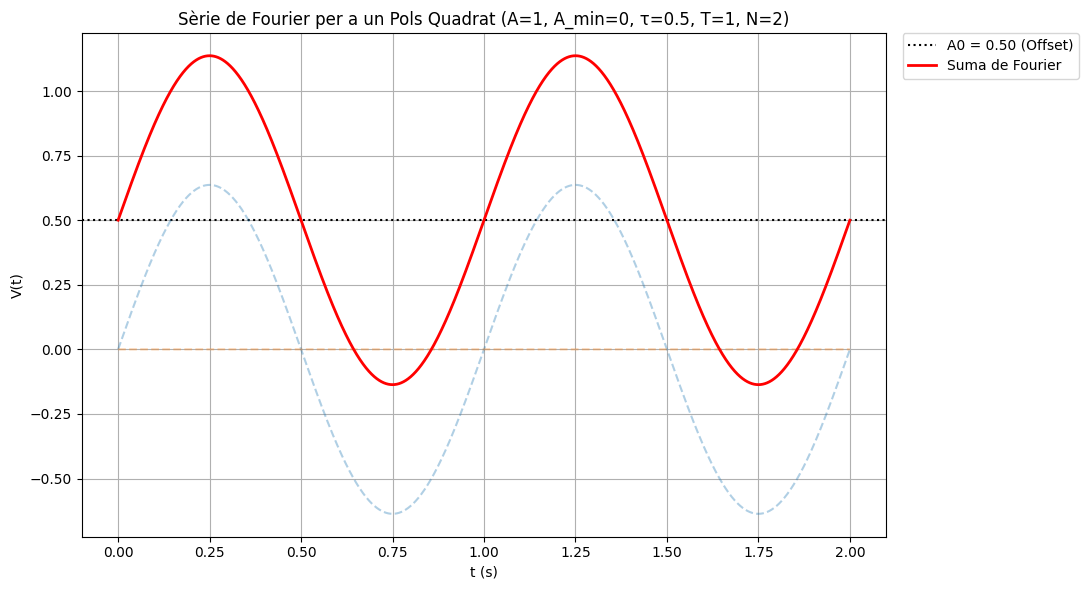

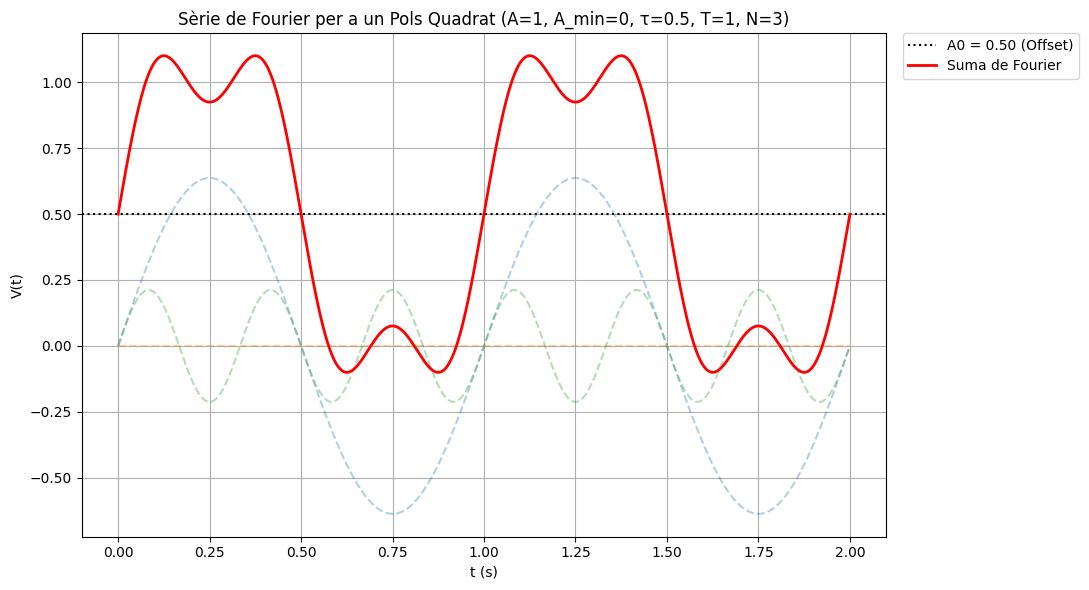

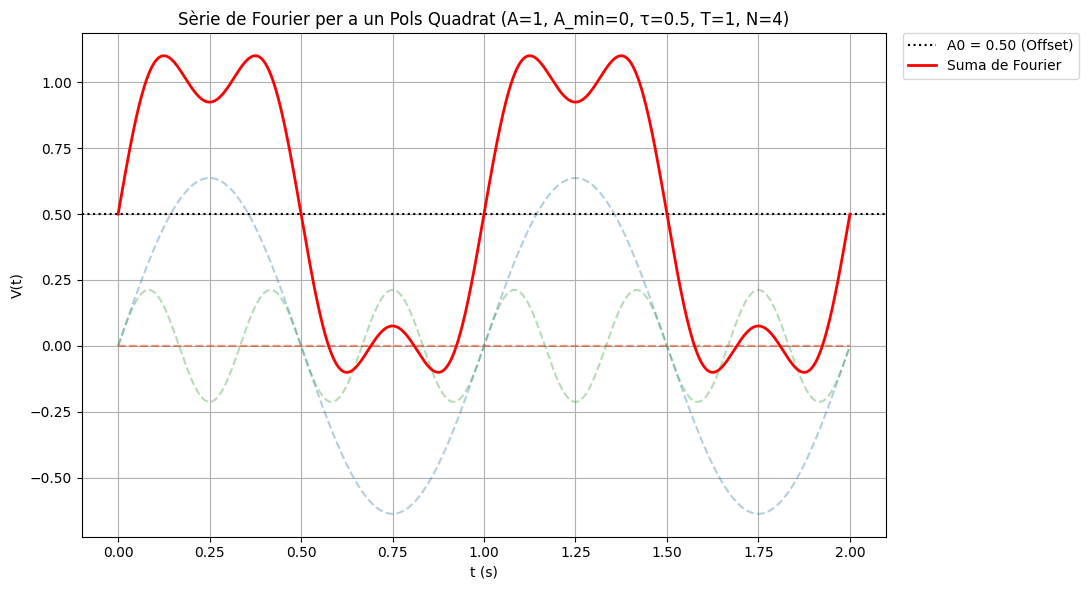

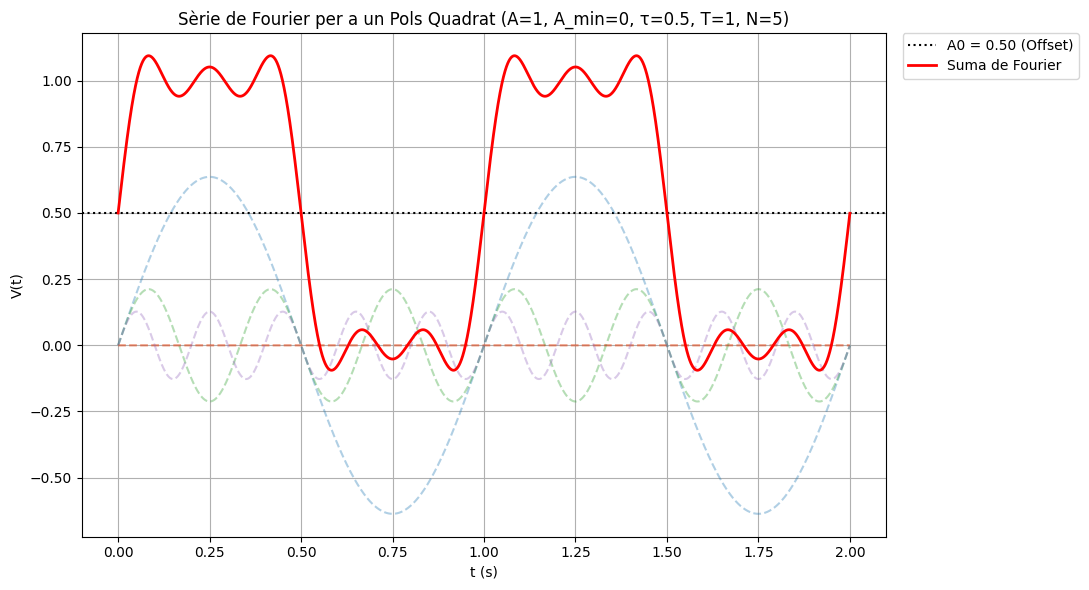

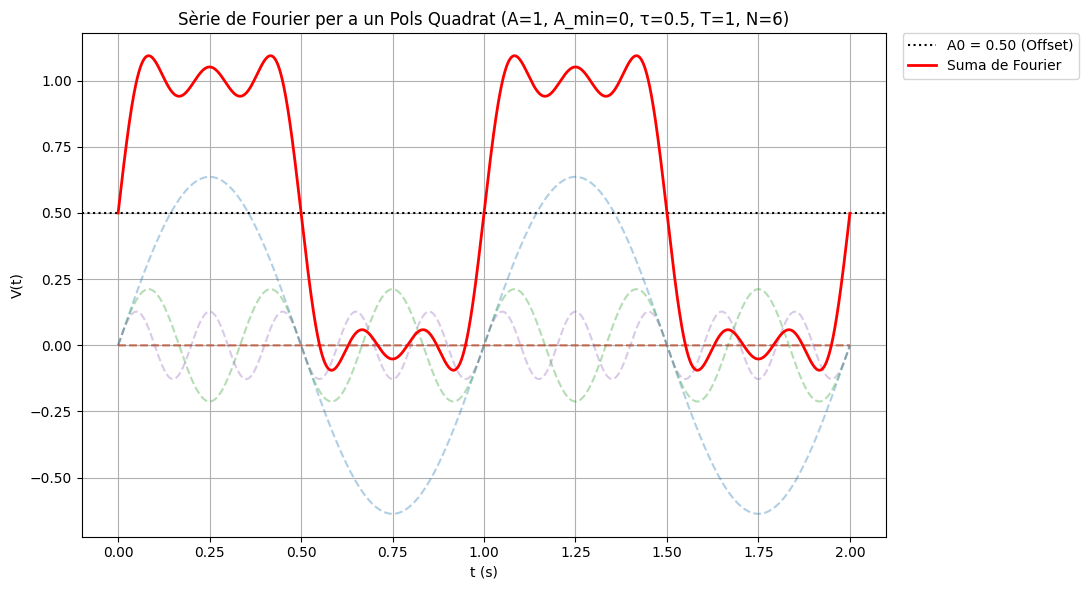

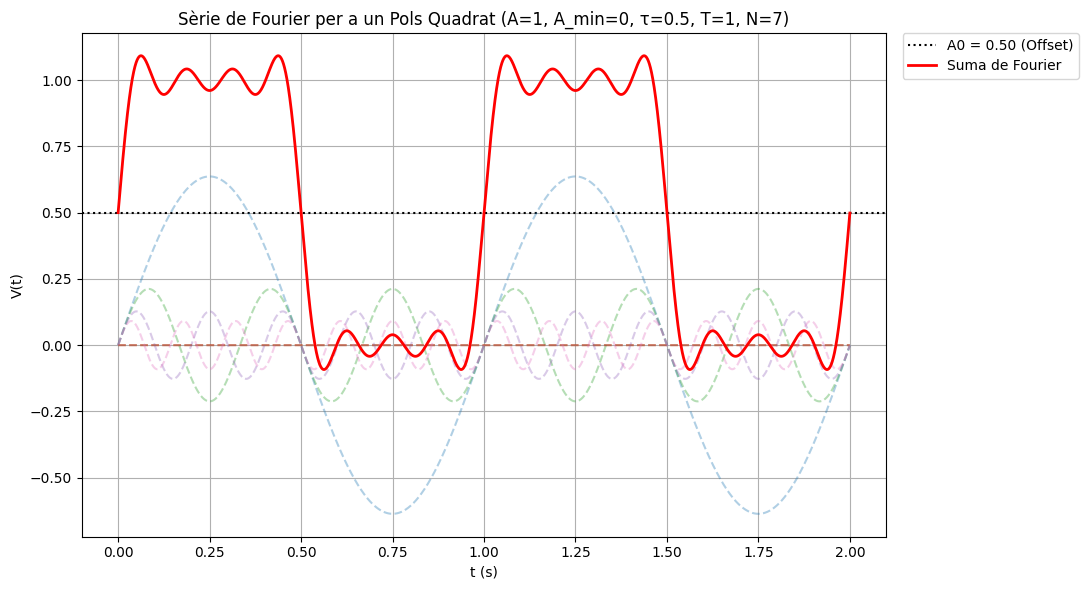

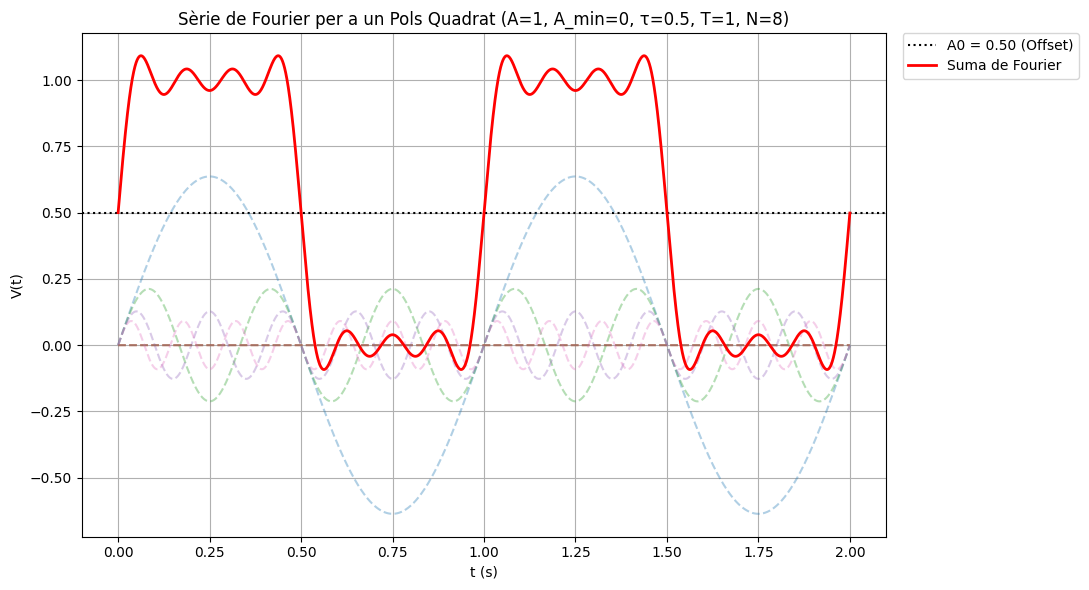

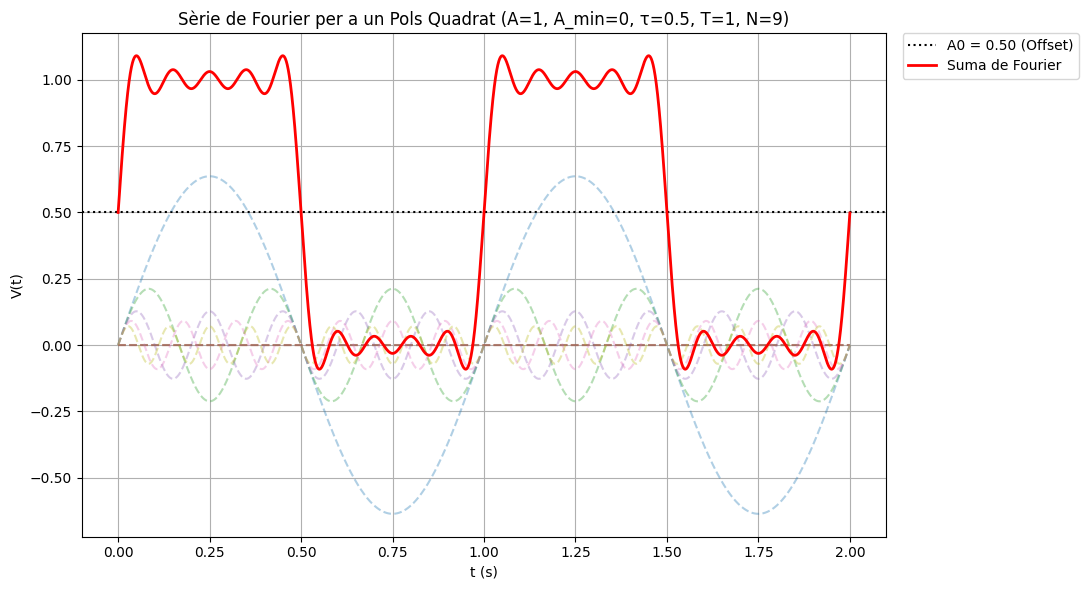

In [ ]:
# Cridada d'exemple: Pols d'amplitud A=1, durada τ=0.5, període T=1 (simètric)
for N in range(10):
    Fourier(wave="square", tmin=0, tmax=2, T=1, t0=0, τ=0.5, A=1, A_min=0, Nharms=N)

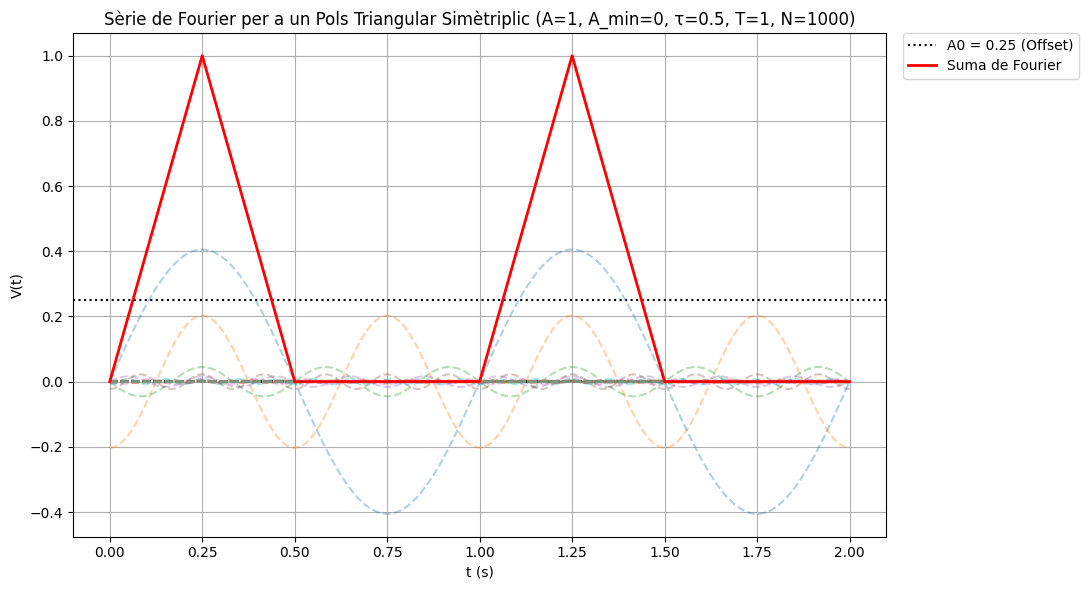

In [ ]:
Fourier(wave="triangular_sym", tmin=0, tmax=2, T=1, t0=0, τ=0.5, A=1, A_min=0, Nharms=1000)

# Enllaços externs.
## Veieu també:

https://www.falstad.com/fourier/Fourier.html

https://www.geogebra.org/m/wUanseCs